# Lecture 30: Linear Regression
v.ekc

Prediction: the nearest-neighbor predictions from Lecture 10 smooth out into a **line**, and using the correlation coefficient r

**Today's sections:**
1. Correlation recap
2. Prediction lines
3. Defining the regression line
4. Heights, regressed

### 📋 Reference Table — the regression line

| Quantity | Formula |
|---|---|
| slope | `r * SD_y / SD_x` |
| intercept | `mean_y - slope * mean_x` |
| in standard units | line through (0,0) with slope **r** |
| prediction | `slope * x + intercept` |

In [1]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
import numpy as np
plots.style.use('fivethirtyeight')

In [2]:
# Some functions for plotting. You don't have to understand how any
# of the functions in this cell work, since they use things we 
# haven't learned about in Data 111.


def resize_window(lim=3.5):
    plots.xlim(-lim, lim)
    plots.ylim(-lim, lim)
    
def draw_line(slope=0, intercept=0, x=make_array(-4, 4), color='#1e90ff'):
    y = x*slope + intercept
    plots.plot(x, y, color=color, lw=3)
    
def draw_vertical_line(x_position, color='black'):
    x = make_array(x_position, x_position)
    y = make_array(-4, 4)
    plots.plot(x, y, color=color, lw=3)
    
def make_correlated_data(r):
    x = np.random.normal(0, 1, 1000)
    z = np.random.normal(0, 1, 1000)
    y = r*x + (np.sqrt(1-r**2))*z
    return x, y

def r_scatter(r):
    """Generate a scatter plot with a correlation approximately r"""
    plots.figure(figsize=(5,5))
    x, y = make_correlated_data(r)
    plots.scatter(x, y, color='darkblue', s=20)
    plots.xlim(-4, 4)
    plots.ylim(-4, 4)
    
def r_table(r):
    """
    Generate a table of 1000 data points with a correlation approximately r
    """
    np.random.seed(8)
    x, y = make_correlated_data(r)
    return Table().with_columns('x', x, 'y', y)

And the standard-units converter, the workhorse of the whole prediction arc:

In [3]:
def standard_units(x):
    "Convert any array of numbers to standard units."
    return (x - np.average(x)) / np.std(x)

---
## 1. Correlation Recap

In [4]:
def correlation(t, x, y):
    """t is a table; x and y are column labels"""
    x_in_standard_units = standard_units(t.column(x))
    y_in_standard_units = standard_units(t.column(y))
    return np.average(x_in_standard_units * y_in_standard_units)

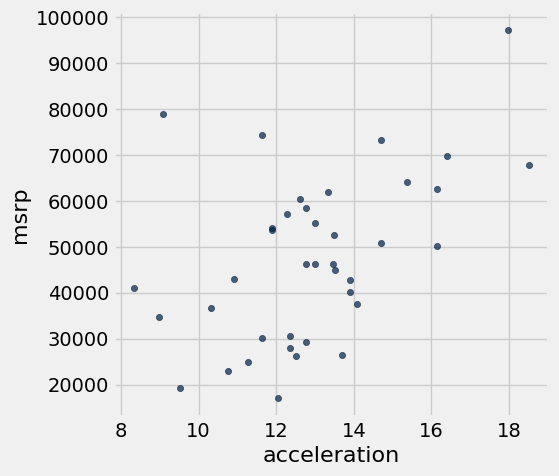

In [5]:
hybrid = Table.read_table('hybrid.csv')
suv = hybrid.where('class', 'SUV')
suv.scatter('acceleration', 'msrp')

In [6]:
correlation(suv, 'acceleration', 'msrp')

0.48699799279959155

### Switching Axes

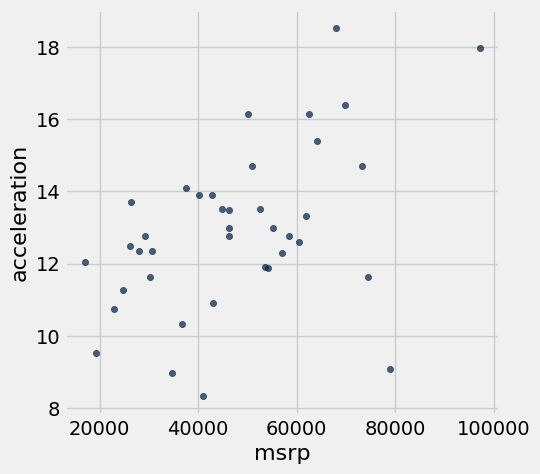

In [7]:
suv.scatter('msrp', 'acceleration')

In [8]:
correlation(suv, 'msrp', 'acceleration')

0.48699799279959155

---
## 2. Prediction Lines

Synthetic data with known r. Watch what the nearest-neighbor predictions do as r drops from 0.99 to 0.

### r = 0.99

In [9]:
example = r_table(0.99)
example.show(3)

x,y
0.0912047,-0.0680119
1.09128,1.04391
-1.94697,-1.88316


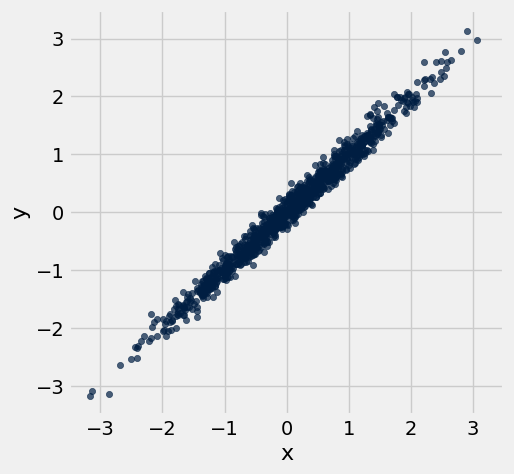

In [10]:
example.scatter('x', 'y')
resize_window()

Nearest neighbors again: average the y values in a thin vertical strip:

In [11]:
def nn_prediction_example(x_val):
    """ Predicts y-value for x based on the example table """
    neighbors = example.where('x', are.between(x_val - .25, x_val + .25))
    return np.mean(neighbors.column('y'))   

In [12]:
nn_prediction_example(-2.25)

-2.1476337989800522

Apply it to every point and plot the predictions in gold:

In [13]:
example = example.with_columns(
    'Predicted y', 
    example.apply(nn_prediction_example, 'x'))

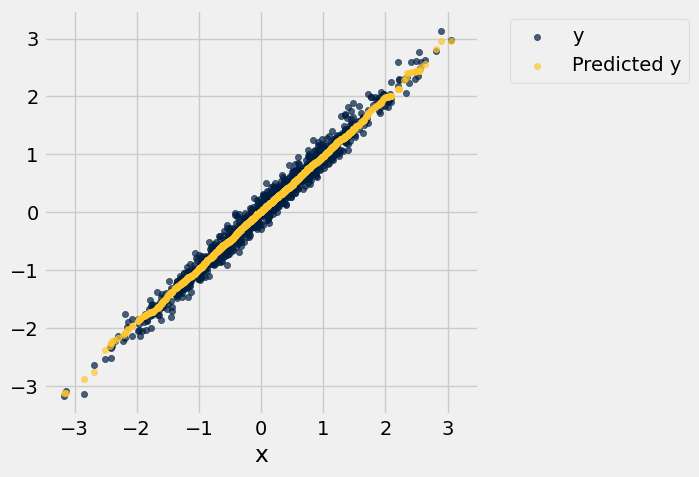

In [14]:
example.scatter('x')
resize_window()

Those predictions hug the 45° line, slope 1:

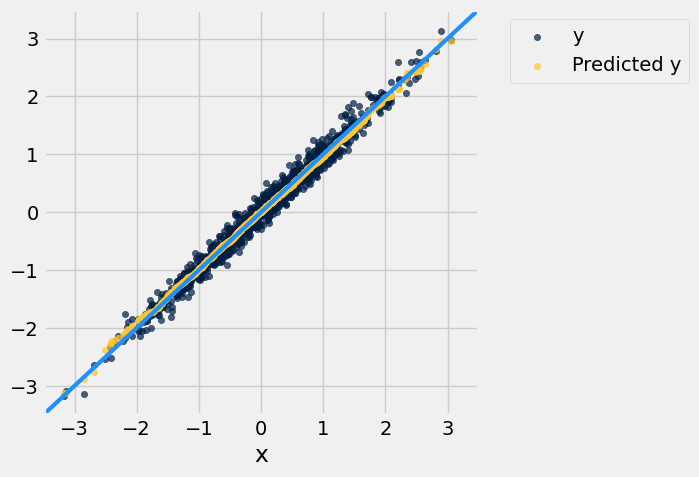

In [15]:
example.scatter('x')
draw_line(slope=1)
resize_window()

### r = 0

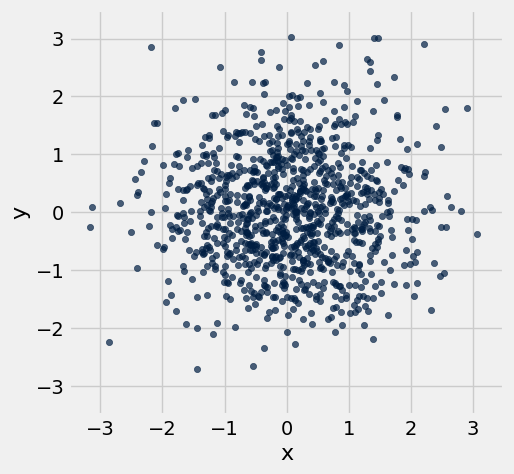

In [16]:
example = r_table(0)
example.scatter('x', 'y')
resize_window()

In [17]:
example = example.with_columns(
    'Predicted y', 
    example.apply(nn_prediction_example, 'x'))

With no association the best prediction is the average, a flat line at slope 0:

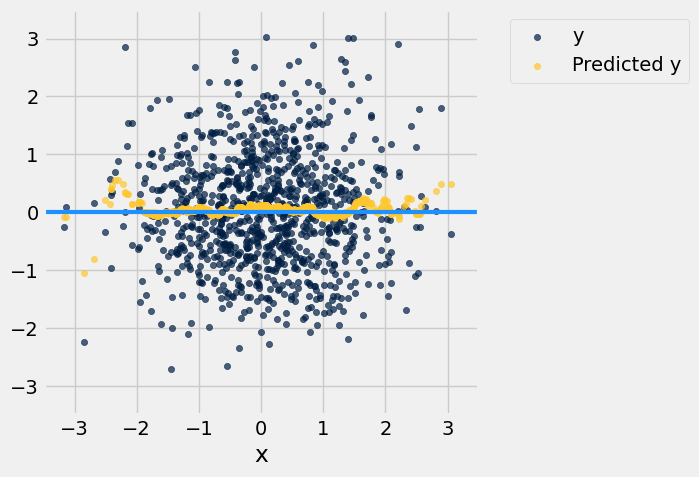

In [18]:
example.scatter('x')
draw_line(slope = 0)
resize_window()

### r = 0.5

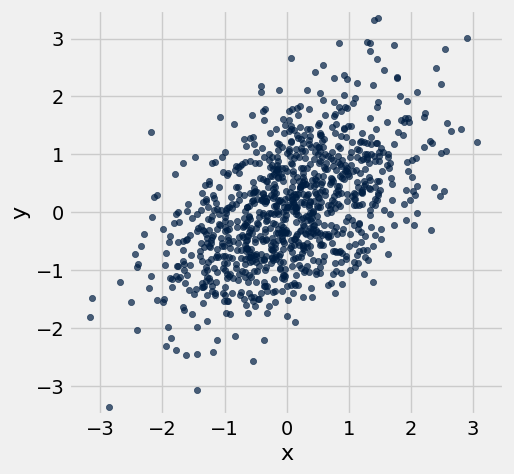

In [19]:
example = r_table(0.5)
example.scatter('x', 'y')
resize_window()

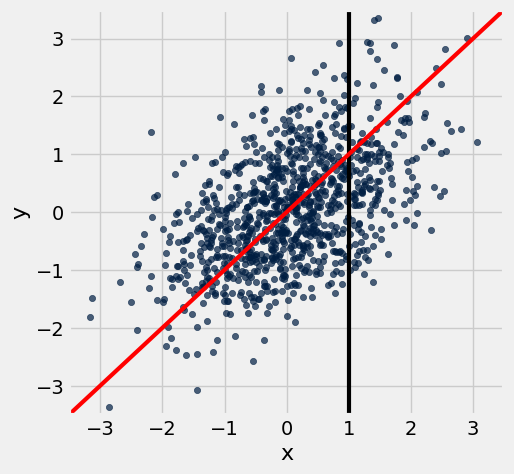

In [20]:
example = r_table(0.5)
example.scatter('x', 'y')
resize_window()
draw_vertical_line(1)
draw_line(slope=1, intercept=0, color='red')

Average that strip: the prediction lands below the red 45° line:

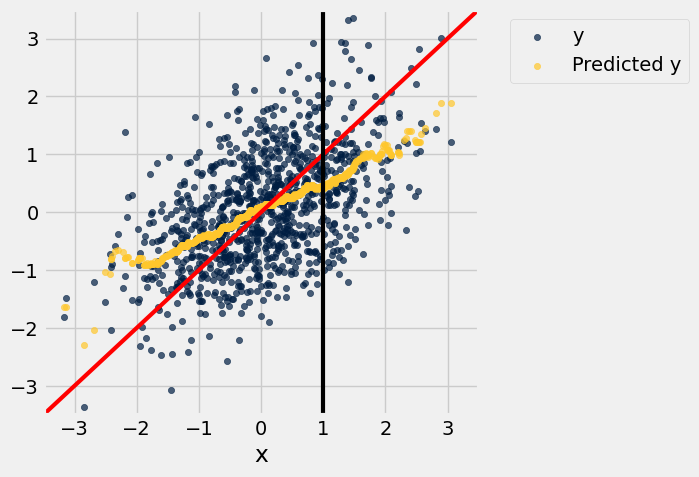

In [21]:
example = example.with_column('Predicted y', example.apply(nn_prediction_example, 'x'))
example.scatter('x')
draw_line(slope=1, color='red')
draw_vertical_line(1)
resize_window()

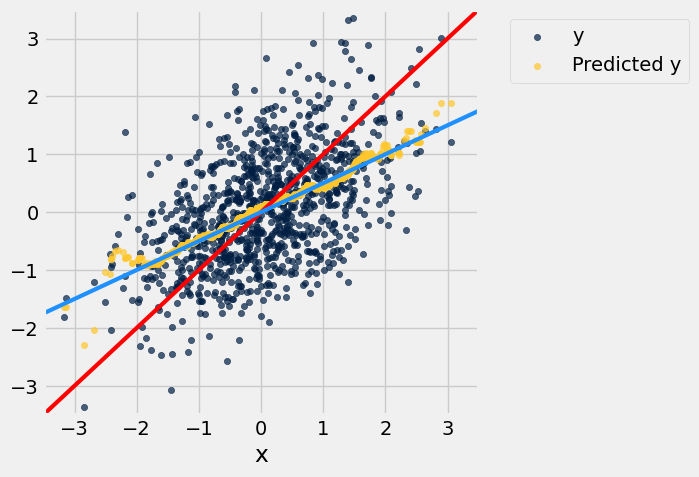

In [22]:
example.scatter('x')
draw_line(slope=1, intercept=0, color='red')
draw_line(slope=0.5, intercept=0)
resize_window()

> **The key picture:** in standard units, the nearest-neighbor predictions hug a line of slope **r**, not the 45° line. Predictions are always *less extreme* than the inputs; that pull toward the average is why it's called "regression."


###  r = 0.7

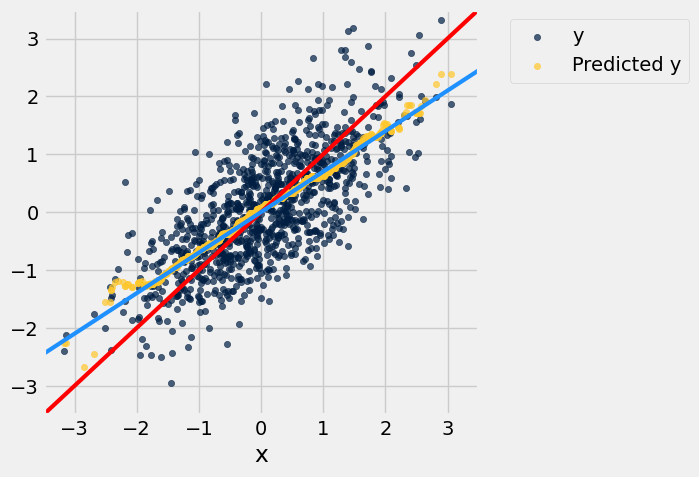

In [23]:
example = r_table(0.7)
example = example.with_column('Predicted y', example.apply(nn_prediction_example, 'x'))
example.scatter('x')
draw_line(slope=1, intercept=0, color='red')
draw_line(slope=0.7, intercept=0, color='dodgerblue')
resize_window()

### Try It 1: Your own r 😊

1. Build `example = r_table(0.3)`, add the nearest-neighbor predictions, and scatter them.

2. Draw both `draw_line(slope=1, intercept=0, color='red')` and `draw_line(slope=0.3, intercept=0, color='dodgerblue')` on the scatter. Which line do the predictions follow?

In [24]:
# 1. r_table(0.3) with predictions


In [25]:
# 2. add both lines


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*The predictions track the slope-0.3 line, exactly the pattern from 0.99, 0.5, and 0.7.*

```python
# 1.
example = r_table(0.3)
example = example.with_column('Predicted y', example.apply(nn_prediction_example, 'x'))
example.scatter('x')
resize_window()

# 2.
example.scatter('x')
draw_line(slope=1, intercept=0, color='red')
draw_line(slope=0.3, intercept=0, color='dodgerblue')
resize_window()
```

</details>

---
## 3. Defining the Regression Line

Out of standard units and into real ones: slope and intercept in three short functions:

In [26]:
# Copy-pasted from above
def standard_units(x):
    """ Converts an array x to standard units """
    return (x - np.mean(x)) / np.std(x)

def correlation(t, x, y):
    """ Computes correlation: t is a table, and x and y are column names """
    x_su = standard_units(t.column(x))
    y_su = standard_units(t.column(y))
    return np.mean(x_su * y_su)

Slope first; the intercept then follows from the means:

In [27]:
def slope(t, x, y):
    """ Computes the slope of the regression line, like correlation above """
    r = correlation(t, x, y)
    y_sd = np.std(t.column(y))
    x_sd = np.std(t.column(x))
    return r * y_sd / x_sd


In [28]:
def intercept(t, x, y):
    """ Computes the intercept of the regression line, like slope above """
    x_mean = np.mean(t.column(x))
    y_mean = np.mean(t.column(y))
    return y_mean - slope(t, x, y)*x_mean

Sanity check on synthetic r = 0.5 data, where the slope should come out near 0.5:

standard units
slope: 0.5022638281625915, y-intercept: 0.03801479544542581


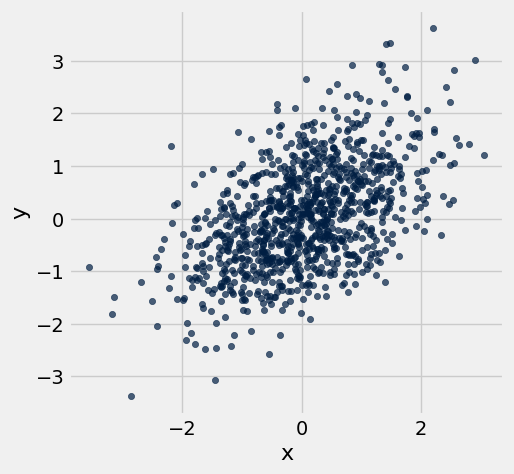

In [45]:
example = r_table(0.5)
example.scatter('x','y')
m=slope(example, 'x', 'y')
b=intercept(example, 'x','y')

print(f'''standard units
slope: {m}, y-intercept: {b}''')

### Try It 2: Slope and intercept, real data 😊

1. Compute the slope and intercept of the regression line for predicting `msrp` from `acceleration` in the `suv` table.

2. Finish the sentence: each additional unit of acceleration is associated with about ______ more dollars of price.

In [34]:
# 1. slope and intercept for suv


*2. Your interpretation: (double-click to edit)*

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*The functions take any table and two column names.*

```python
# 1.
slope(suv, 'acceleration', 'msrp'), intercept(suv, 'acceleration', 'msrp')    # about 3911 and -2911
```

*2. About \$3,900 more per unit of acceleration, for the hybrid SUVs in this dataset.*

</details>

---
## 4. Heights, Regressed

Full circle: Lecture 10's nearest-neighbor predictions vs. the regression line, on Galton's data.

In [35]:
# Note: Child heights are the **adult** heights of children in a family
families = Table.read_table('family_heights.csv')
parent_avgs = (families.column('father') + families.column('mother'))/2
heights = Table().with_columns(
    'Parent Average', parent_avgs,
    'Child', families.column('child'),
)
heights.show(5)

Parent Average,Child
72.75,73.2
72.75,69.2
72.75,69
72.75,69
71,73.5


Lecture 10's nearest-neighbor recipe, one more time:

In [36]:
def nn_prediction_height(p_avg):
    """Predict the height of a child whose parents have a parent average height of p_avg.
    
    The prediction is the average height of the children whose parent average height is
    in the range p_avg plus or minus 0.5.
    """
    
    close_points = heights.where('Parent Average', are.between(p_avg-0.5, p_avg + 0.5))
    return np.average(close_points.column('Child')) 

In [37]:
heights_with_predictions = heights.with_column(
    'Nearest neighbor prediction', 
    heights.apply(nn_prediction_height, 'Parent Average'))
heights_with_predictions.show(5)

Parent Average,Child,Nearest neighbor prediction
72.75,73.2,70.1
72.75,69.2,70.1
72.75,69,70.1
72.75,69,70.1
71,73.5,70.4158


There it is, the graph of averages:

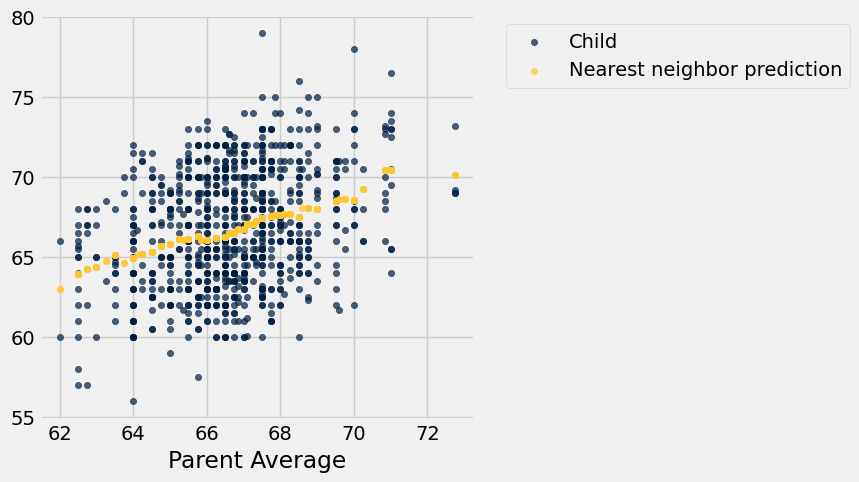

In [38]:
heights_with_predictions.scatter('Parent Average')

Now the line: slope and intercept straight from the formulas:

In [47]:
predicted_heights_slope = slope(heights, 'Parent Average', 'Child')
predicted_heights_intercept = intercept(heights, 'Parent Average', 'Child')
[predicted_heights_slope, predicted_heights_intercept]


print(f'''parents height v child height
slope: {predicted_heights_slope}, y-intercept: {predicted_heights_intercept}''')

parents height v child height
slope: 0.6644952623525884, y-intercept: 0.6644952623525884


In [40]:
heights_with_predictions = heights_with_predictions.with_column(
    'Regression Prediction', 
    predicted_heights_slope*heights.column('Parent Average') + predicted_heights_intercept
)
heights_with_predictions

Parent Average,Child,Nearest neighbor prediction,Regression Prediction
72.75,73.2,70.1,70.8039
72.75,69.2,70.1,70.8039
72.75,69,70.1,70.8039
72.75,69,70.1,70.8039
71,73.5,70.4158,69.641
71,72.5,70.4158,69.641
71,65.5,70.4158,69.641
71,65.5,70.4158,69.641
69.5,71,68.5025,68.6443
69.5,68,68.5025,68.6443


Both predictions on one scatter, nearly indistinguishable:

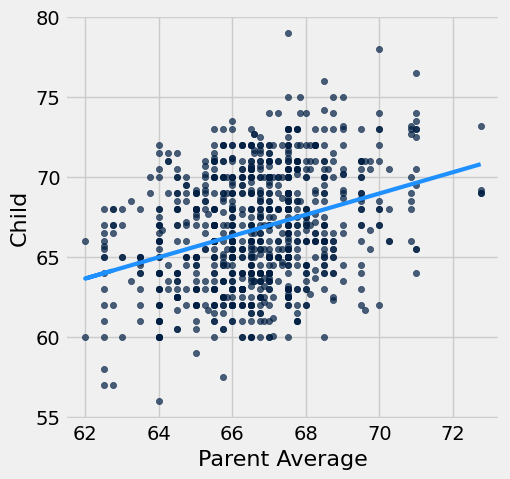

In [48]:
# plot with regression line!

heights_with_predictions.scatter('Parent Average', 'Child')
draw_line(slope =predicted_heights_slope,
         intercept =predicted_heights_intercept,
         x=heights.column('Parent Average'))

#heights_with_predictions.scatter('Parent Average')

> **The line goes right through the graph of averages**: regression is nearest-neighbor prediction, smoothed.

### Try It 3: Predict with the line 😊

1. Use `predicted_heights_slope` and `predicted_heights_intercept` to predict the height of a child whose parents average 68 inches. Compare with Lecture 29's nearest-neighbor answer (≈ 67.6).

In [42]:
# 1. slope * 68 + intercept


<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*One multiplication and one addition, no table filtering needed.*

```python
# 1.
predicted_heights_slope * 68 + predicted_heights_intercept   # ≈ 67.65
```

</details>

### Predicting in standard units

In standard units, the regression line has slope r. So a prediction needs only the means, the SDs, and r. A class has midterm scores with mean 70 and SD 10, and final scores with mean 50 and SD 12. The correlation between the two scores is 0.75. Predict the final score of a student who scored 90 on the midterm:

1. Convert the midterm score to standard units.
2. Multiply by r to get the prediction in standard units.
3. Convert back to the original units of the final.

Then predict the final score of a student who scored 60 on the midterm.

In [30]:
# x variable: midterm scores
midterm_mean = 70
midterm_sd = 10

# y variable: final scores
final_mean = 50
final_sd = 12

# Correlation (relates x to y values)
corr = 0.75

# new observation's x value
midterm_student = 90

In [31]:
midterm_student_su = (midterm_student - midterm_mean) / midterm_sd
midterm_student_su

2.0

In [32]:
final_student_su = midterm_student_su * corr
final_student_su

1.5

In [33]:
final_student = final_student_su * final_sd + final_mean
final_student

68.0

<details>
<summary>💡 Possible answers — click to peek</summary>
<br>

*Midterm 90 is (90 − 70)/10 = 2 standard units. Multiply by r: 2 × 0.75 = 1.5 standard units. Back to the final's units: 1.5 × 12 + 50 = 68.*

*For a midterm score of 60, set `midterm_student = 60` and rerun: (60 − 70)/10 = −1 standard unit, × 0.75 = −0.75, and −0.75 × 12 + 50 = 41.*

*The regression line in original units gives the same answers. Its slope is 0.75 × 12/10 = 0.9 and its intercept is 50 − 0.9 × 70 = −13, so the line is y = 0.9x − 13: 0.9 × 90 − 13 = 68 and 0.9 × 60 − 13 = 41.*

```python
# midterm 60
midterm_student = 60
((midterm_student - midterm_mean) / midterm_sd) * corr * final_sd + final_mean    # 41.0
```

</details>

---
> **Today's takeaway:** slope = r·SDy/SDx, intercept = meany − slope·meanx, and the line is the smoothed graph of averages. Lab 9 investigates this line from every angle.

## Appendix — Quick Reference

Full `datascience` docs: [data8.org/datascience](https://data8.org/datascience/)

### Minimal template — regression prediction
```python
def slope(t, x, y):
    return correlation(t, x, y) * np.std(t.column(y)) / np.std(t.column(x))

def intercept(t, x, y):
    return np.mean(t.column(y)) - slope(t, x, y) * np.mean(t.column(x))
```